In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial import ConvexHull
from sklearn.decomposition import PCA
from tqdm.notebook import tqdm

### Подгружаем данные о подструктурах

In [2]:
def get_min_distance_to_hull(positions:np.ndarray):
    """
    Находит минимальное расстояние от поглощающего атома внутри ConvexHull до его поверхности.
    """
    p = np.array([0,0,0])
    hull = ConvexHull(positions)
    A_B_C = hull.equations[:, :-1]  # Матрица нормалей (N, 3)
    D = hull.equations[:, -1]       # Вектор сдвигов (N,)
    distances = np.abs(np.dot(A_B_C, p) + D)
    return np.min(distances).round(4)

In [3]:
unique_substructures_df = pd.read_pickle('../source_data/INIT_unique_substructures_Rcut_7.5_stephist_0.1.pkl')
BASE_DF = unique_substructures_df.copy()
BASE_DF['CN4'] = BASE_DF.CN.apply(lambda x: x[:4])
BASE_DF['CN1245'] = BASE_DF.CN.apply(lambda x: x[[0,1,3,4]])
BASE_DF['size'] =  BASE_DF['Structure'].apply(lambda x: x.get_all_distances().max().round(4))
BASE_DF['surface_proximity'] =  BASE_DF['Structure'].apply(lambda x: get_min_distance_to_hull(x.positions))
BASE_DF['surface_proximity_normed'] = BASE_DF['surface_proximity']/BASE_DF['size']

### Подгружаем размазанные спектры

In [4]:
SPECTRA_ROOT = Path('../processed_data/conv_dense_spectra/')
SPECTRA_PATH_LIST = sorted(list(SPECTRA_ROOT.iterdir()), key=lambda x: int(x.name.split('.')[0]))

In [5]:
# Т.к. все рассматриваемые НК не подвергались релаксации, можно ожидать что дальняя область спектра у них должна быть схожей (близка к фольге).
# Поэтому для сопоставления спектров выберем диапазон ближе к дальнему хвосту спектра, по которому будем их нормировать.
E_min_norm, E_max_norm = 25, 40

In [6]:
# Загружаем экспериментальный спектр фольги
foil_spectrum_exp = np.loadtxt('../source_data/PtL3_foil.txt')
# Выравнивание эксперимента по краю поглощения (максимум производной)
d_exp = (foil_spectrum_exp[1:, 1] - foil_spectrum_exp[:-1, 1]) / (foil_spectrum_exp[1:, 0] - foil_spectrum_exp[:-1, 0])
# Находим индекс максимального наклона и соответствующую энергию края
E_edge_exp = foil_spectrum_exp[np.argmax(d_exp), 0]

# Переводим экспериментальную сетку в относительную шкалу (E - E_edge)
EXPERIMENT = foil_spectrum_exp.copy()
EXPERIMENT[:, 0] = foil_spectrum_exp[:, 0] - E_edge_exp
exp_mask = (EXPERIMENT[:, 0]>E_min_norm)&(EXPERIMENT[:, 0]<E_max_norm)
EXPERIMENT[:, 1] = EXPERIMENT[:, 1]/(EXPERIMENT[:, 1][exp_mask].max())

In [7]:
# Мы знаем что все размазанные спектры имеют общую шкалу энергий, сохраним ее и определим маску для нормировки
theory_E_array = np.loadtxt(SPECTRA_PATH_LIST[0])[:,0]
theory_mask = (theory_E_array>E_min_norm)&(theory_E_array<E_max_norm)

In [8]:
%%time
# Кэшируем спектры нормированные спектры
normded_spectra_y_cache = {}
for ind in tqdm(unique_substructures_df.index.to_list()):
    spectra_y = np.loadtxt(SPECTRA_PATH_LIST[ind])[:,1]
    spectra_y = spectra_y/(spectra_y[theory_mask].max())
    normded_spectra_y_cache[ind]=spectra_y

  0%|          | 0/2151 [00:00<?, ?it/s]

CPU times: total: 8.23 s
Wall time: 8.21 s


In [9]:
SAVE_IMAGE_PATH = Path('../images/')
def plot_XANES(df:pd.DataFrame, mode:str = 'N_atoms'):
    
    assert mode in ['N_atoms','CN'], 'mode can be "N_atoms" or "CN"'
    
    indexes = df.index.values
    base_title = f'Pt L3-edge XANES Average spectrum of {len(indexes)} examples\n for NC with '

    if mode == 'N_atoms':
        var_title = f'{df.Num_atoms.min()} atoms' if df.Num_atoms.min() == df.Num_atoms.max() else f'N_atoms in range [{df.Num_atoms.min()}, {df.Num_atoms.max()}]'
        title = base_title+var_title
        save_name = title[:]
        save_name = save_name.replace(' ','_').replace('\n','_')
    else:
        cn_values = np.array(df.CN.values.tolist())
        cn_mean = cn_values.mean(axis=0)
        cn_std = cn_values.std(axis=0)
        template = []
        save_template = []
        for ind in range(cn_mean.shape[0]):
            mean_val = cn_mean[ind]
            std_val = cn_std[ind]
            if std_val == 0:
                cn_substr = rf"$\mathbf{{{mean_val:.1f}}}$, "
                save_t = f'{mean_val:.1f}, '
            else:
                cn_substr = rf"$\mathit{{{mean_val:.1f}}}\pm{std_val:.1f}$, "
                save_t = f'{mean_val:.1f}pm{std_val:.1f}, '

            template.append(cn_substr)
            save_template.append(save_t)
            
        var_title ='CN ' + "".join(template).rstrip(", ")   # убираем последнюю запятую и пробел
        var_save = 'CN ' + "".join(save_template).rstrip(", ")
        
        title = base_title+var_title
        save_name = base_title+var_save
        save_name = save_name.replace(' ','_').replace('\n','_')
        
    all_y = np.array([normded_spectra_y_cache[ind] for ind in indexes])
    
    x_axis = theory_E_array

    mean_y = np.mean(all_y, axis=0)
    min_y = np.min(all_y, axis=0)
    max_y = np.max(all_y, axis=0)

    std_y = np.std(all_y, axis=0)
    lower_bound = mean_y - std_y
    upper_bound = mean_y + std_y

    plt.figure(figsize=(8, 5))
    plt.title(title)
    
    plt.fill_between(x_axis, min_y, max_y, color='gray', alpha=0.2, label='Range (min-max)')
    
    plt.plot(x_axis, mean_y, color='mediumblue', linewidth=2, label='Mean Spectrum')

    plt.fill_between(x_axis, lower_bound, upper_bound, color='royalblue', alpha=0.3, label='Std')

    # Experiment
    plt.plot(EXPERIMENT[:,0], EXPERIMENT[:,1], color='black', ls='--',lw=1.5, label='Foil', alpha=0.7)
    
    plt.xlabel('Energy (E-E0), eV')
    plt.ylabel('XANES, arb.unit')
    plt.legend(loc='lower right')
    plt.xlim(-10,60)

    save_path = Path(SAVE_IMAGE_PATH,f'{save_name}.png')
    plt.savefig(save_path, dpi=600)
    
    plt.show()

## Посмотрим на спектры для НК с одинаковым кол-вом атомов

In [10]:
unique_n_atoms = sorted(unique_substructures_df.Num_atoms.unique().tolist())

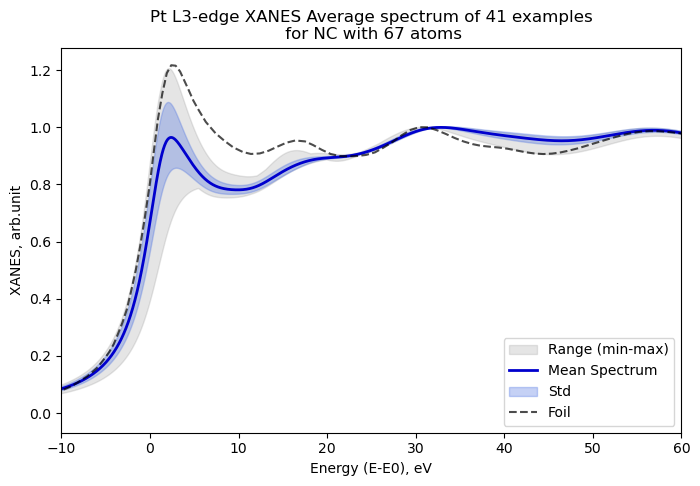

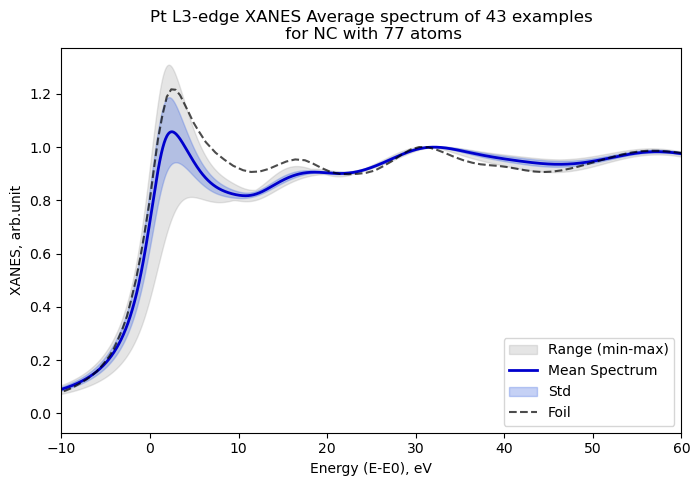

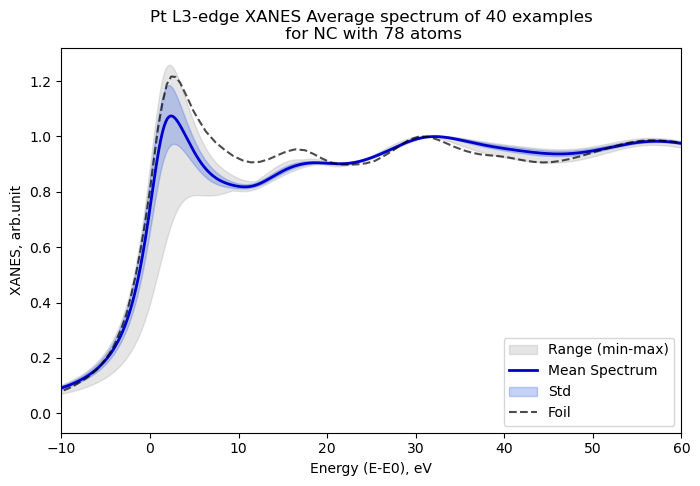

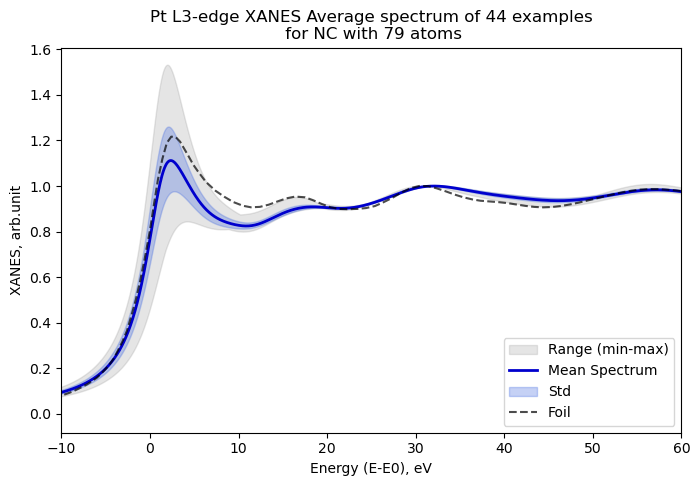

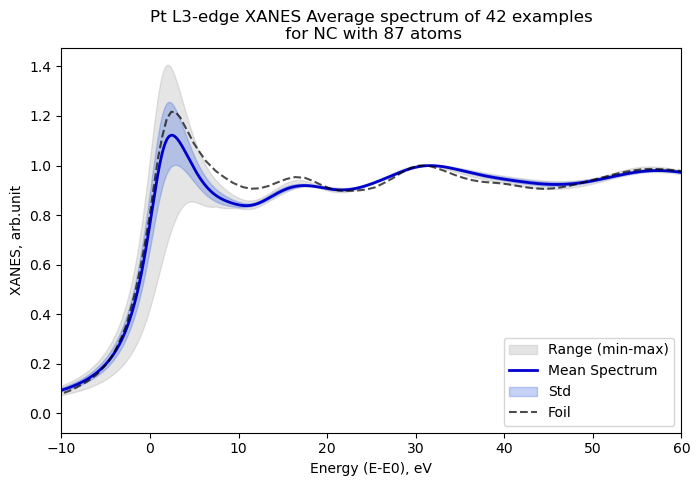

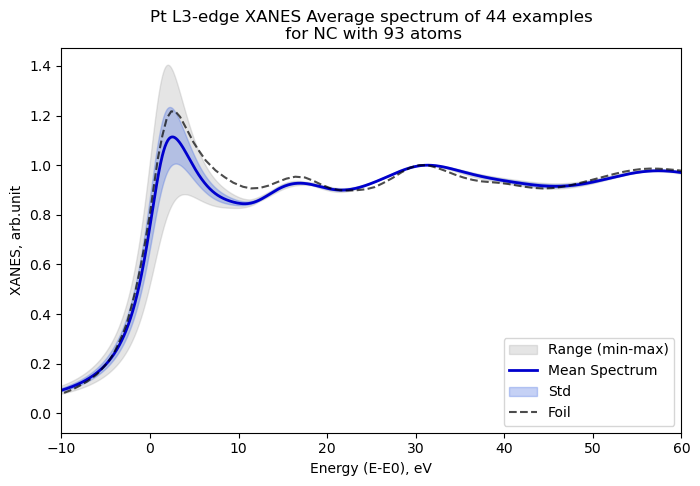

In [11]:
threshold = 40   # мин. кол-во спектров в разбиении для отрисовки

for n_atoms in unique_n_atoms:
    tdf = BASE_DF.query(f'Num_atoms=={n_atoms}')
    if tdf.shape[0]<threshold:
        continue
    plot_XANES(tdf,mode='N_atoms')

## Посмотрим на спектры для НК разбитых на бины по кол-ву атомов

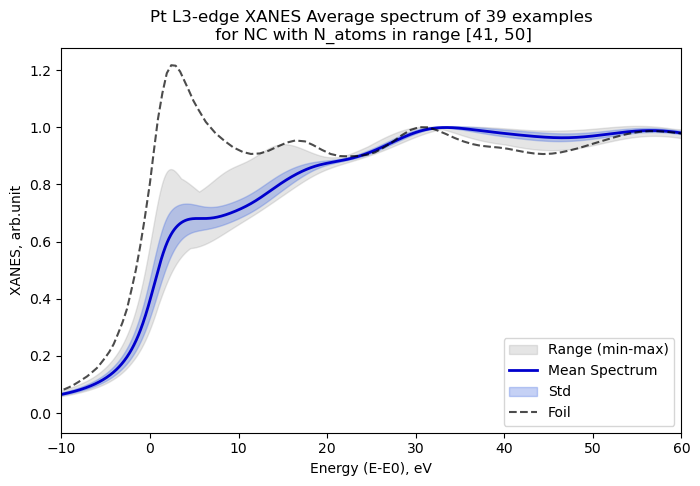

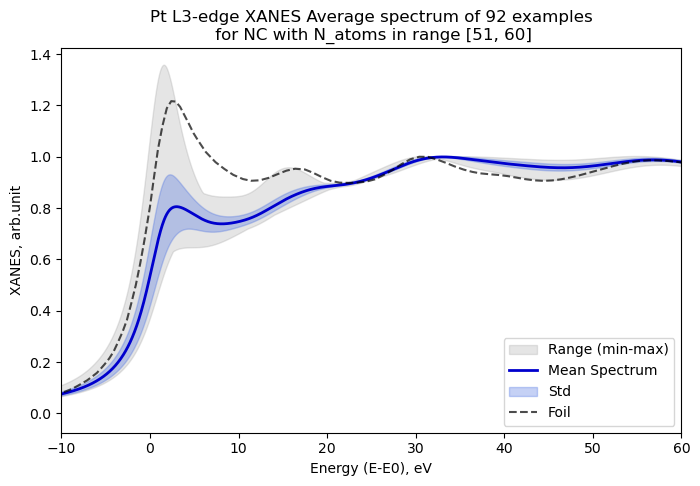

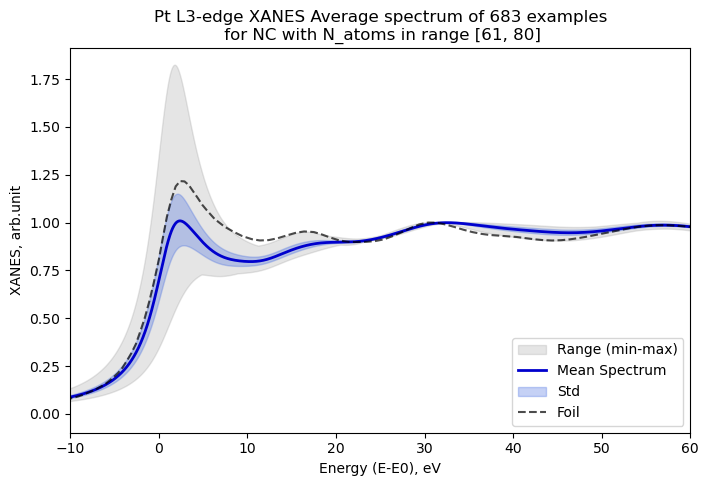

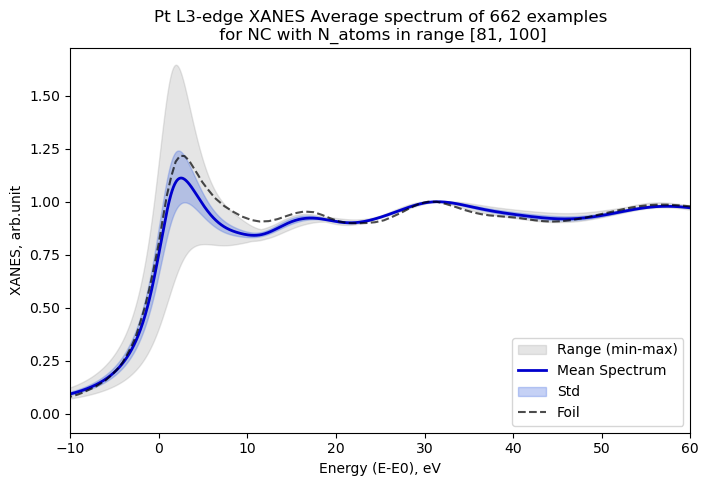

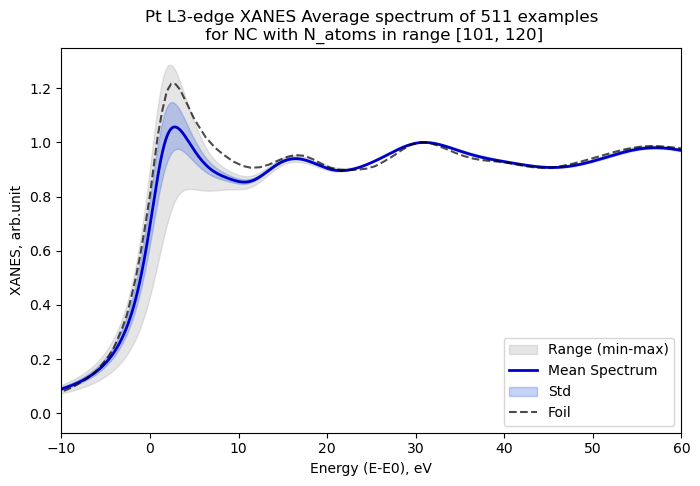

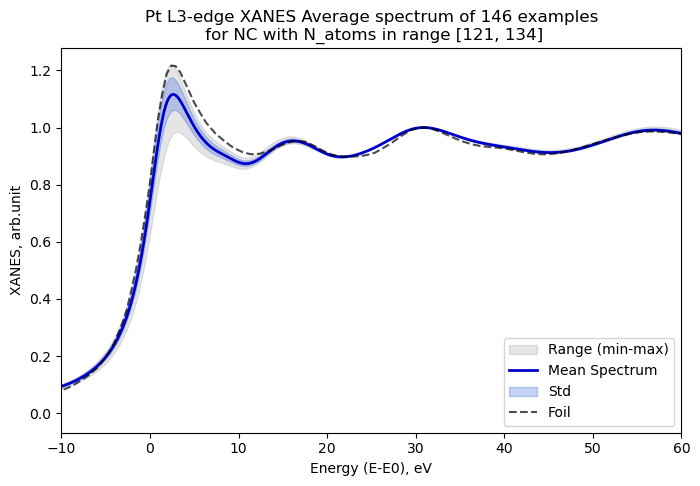

In [12]:
BINS = (0,20,30,40,50,60,80,100,120,134,136)
# BINS = tuple([0]+sorted(unique_substructures_df.Num_atoms.unique().tolist()))

threshold = 30

for start, end in zip(BINS[:-1], BINS[1:]):
    tdf = BASE_DF.query(f'Num_atoms>{start} and Num_atoms<={end}').copy()
    if tdf.shape[0]<threshold:
        continue
    plot_XANES(tdf,mode='N_atoms')

## Посмотрим на спектры с одинаковым набором первых 4 координационных чисел (КЧ)

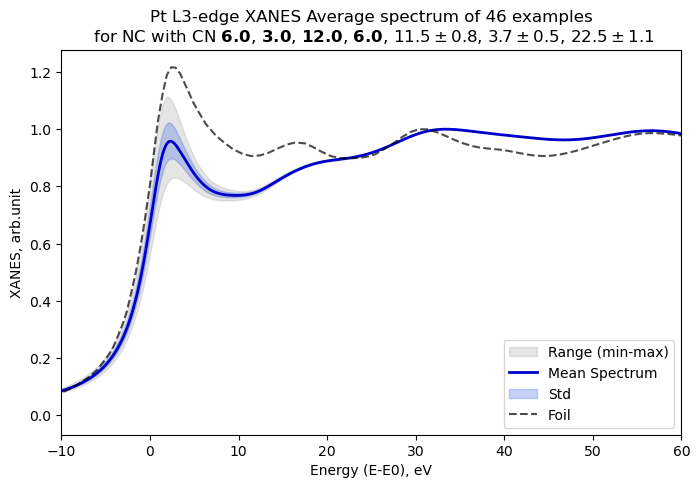

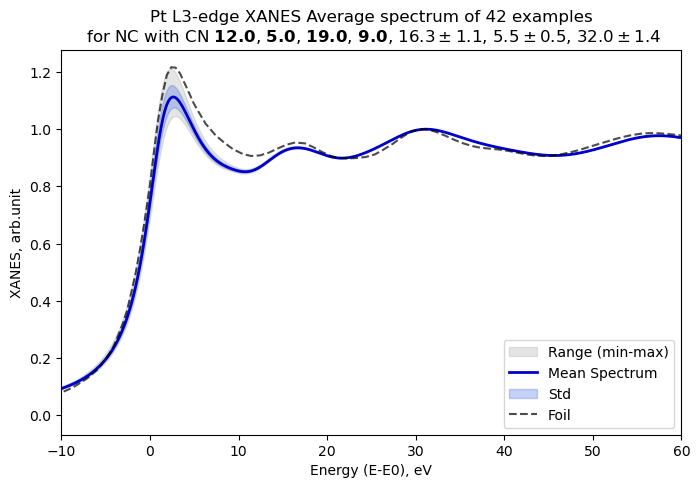

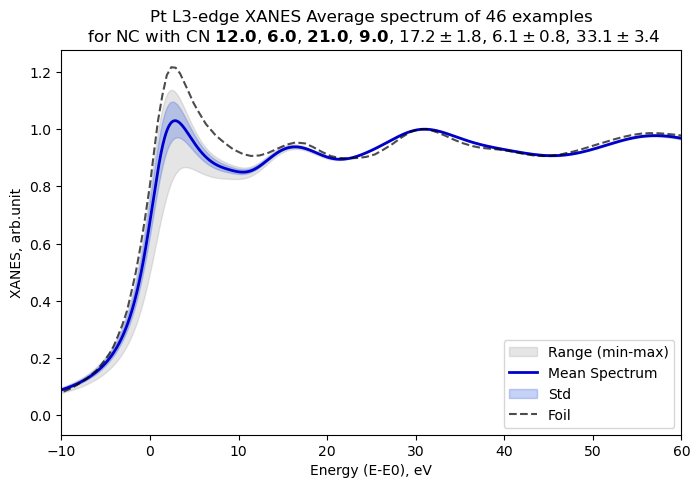

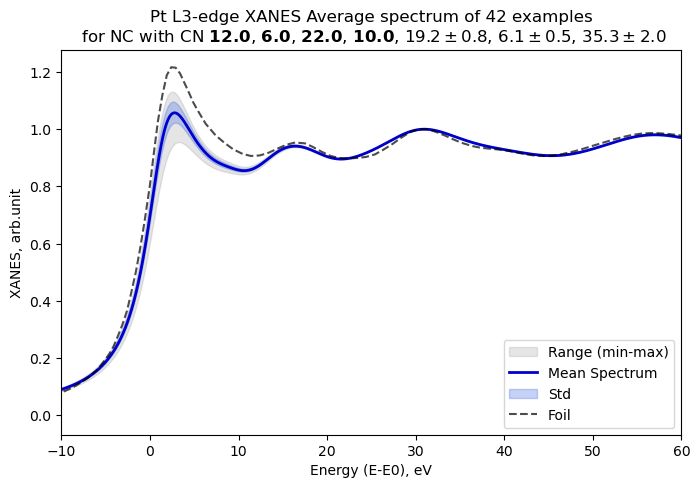

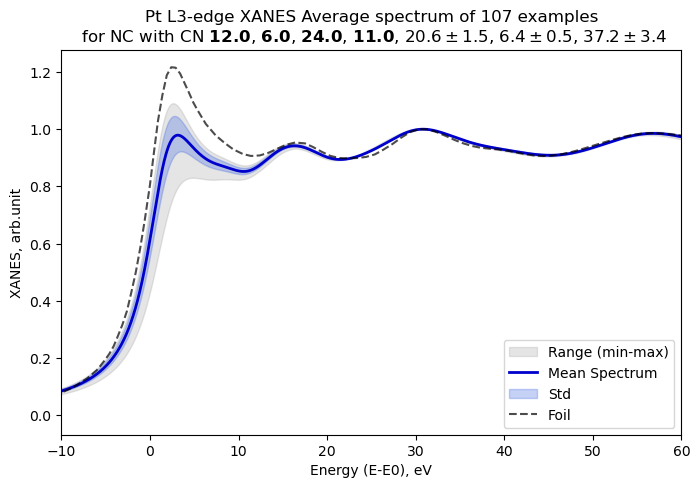

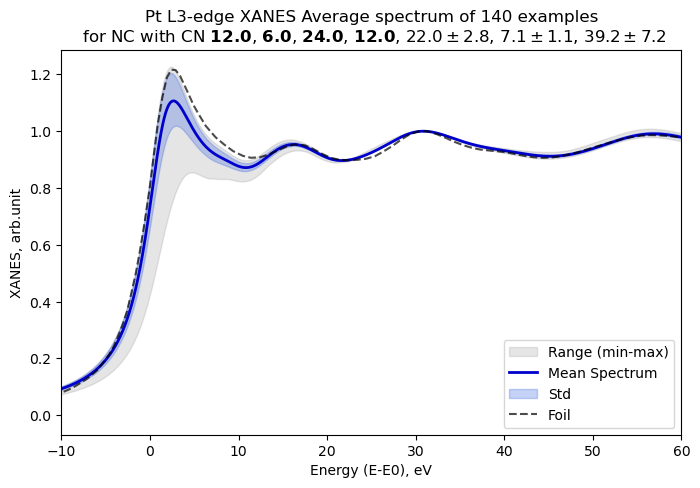

In [13]:
threshold = 40

CN4 = np.array(BASE_DF.CN4.values.tolist())
unique, indices, inverse, counts = np.unique(CN4, return_counts=True, return_index=True, return_inverse=True, axis=0)

selected_group_ids = np.where(counts > threshold)[0]

for group_id in selected_group_ids:
    # Находим индексы строк в DataFrame, которые относятся к данной группе CN
    sample_indices = np.where(inverse == group_id)[0]
    tdf = BASE_DF.loc[sample_indices]
    plot_XANES(tdf,mode='CN')

## Посмотрим на спектры с одинаковым набором 1,2,4 и 5 координационных чисел (КЧ)

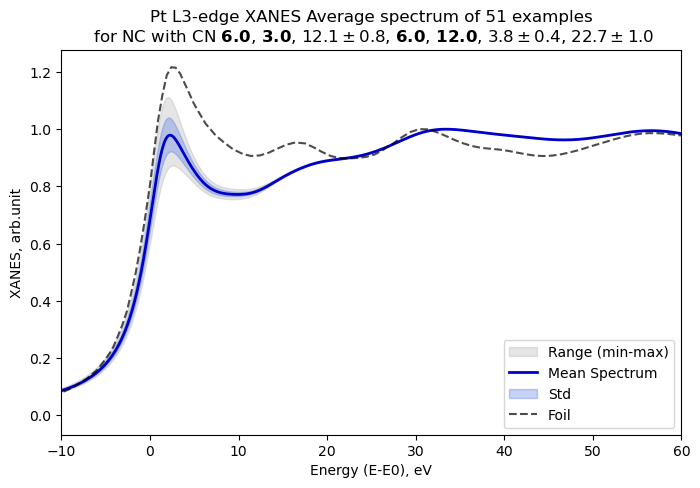

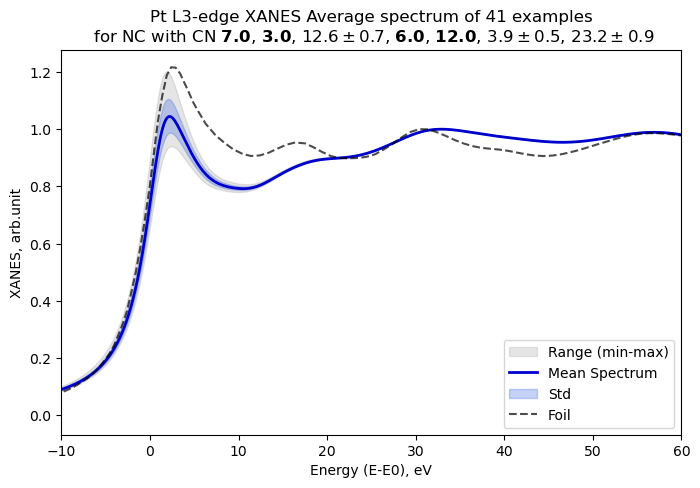

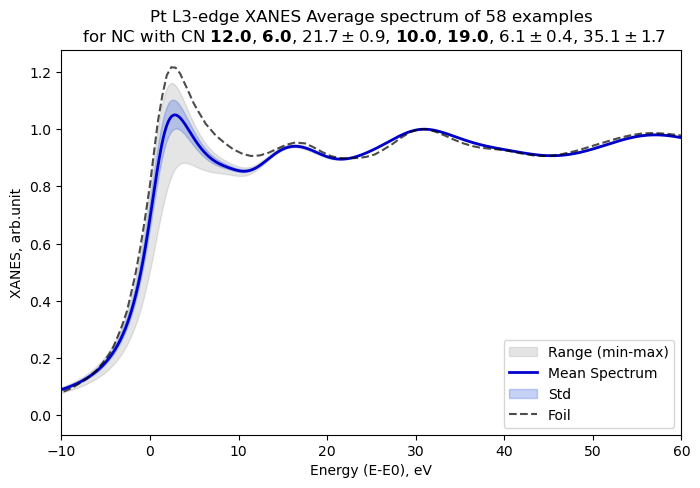

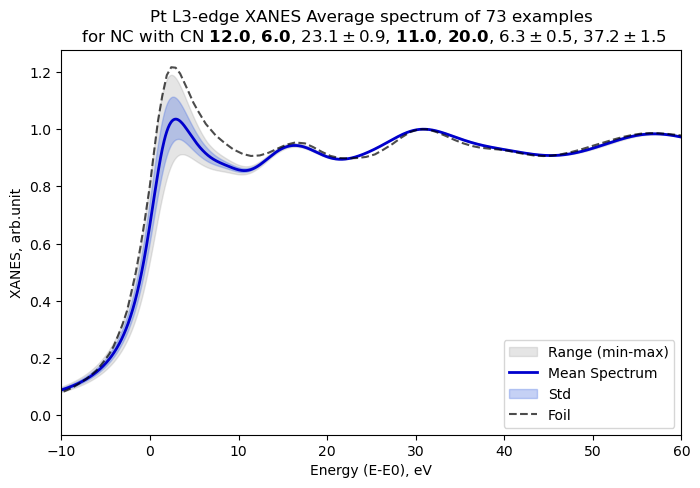

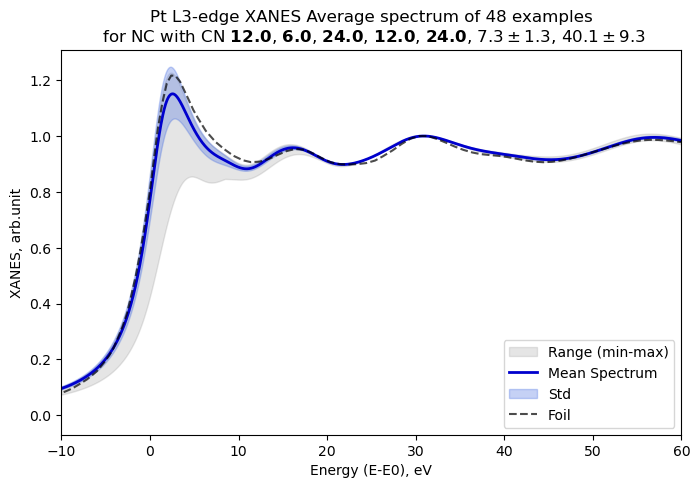

In [14]:
threshold = 40

CN4 = np.array(BASE_DF.CN1245.values.tolist())
unique, indices, inverse, counts = np.unique(CN4, return_counts=True, return_index=True, return_inverse=True, axis=0)

selected_group_ids = np.where(counts > threshold)[0]

for group_id in selected_group_ids:
    # Находим индексы строк в DataFrame, которые относятся к данной группе CN
    sample_indices = np.where(inverse == group_id)[0]
    tdf = BASE_DF.loc[sample_indices]
    plot_XANES(tdf,mode='CN')

## Посмотрим на спектры с одинаковым набором всех 7 доступных координационных чисел (КЧ)

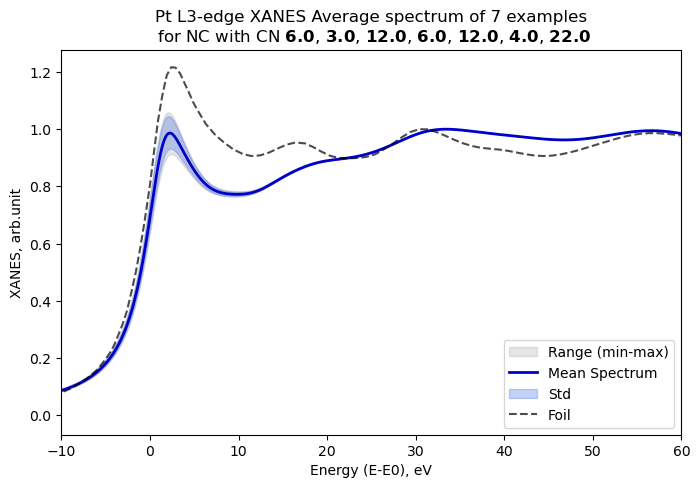

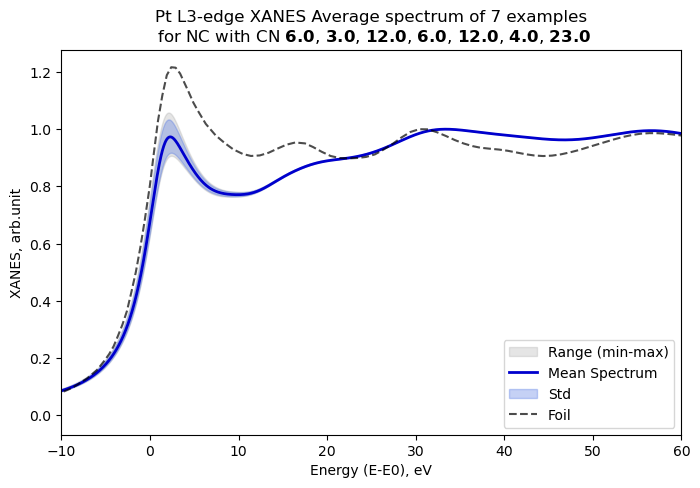

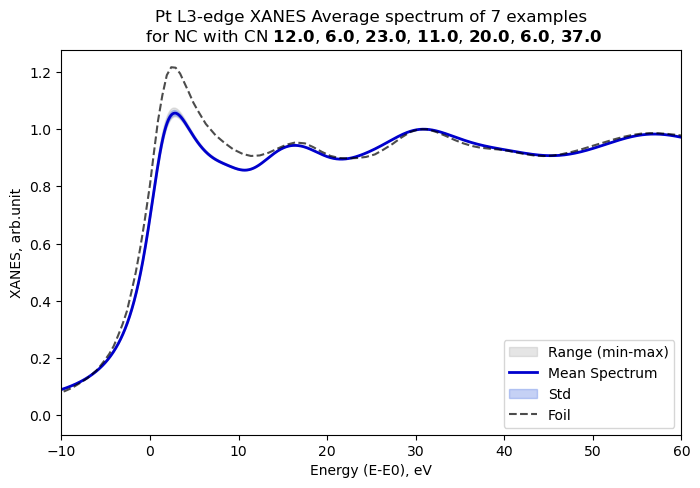

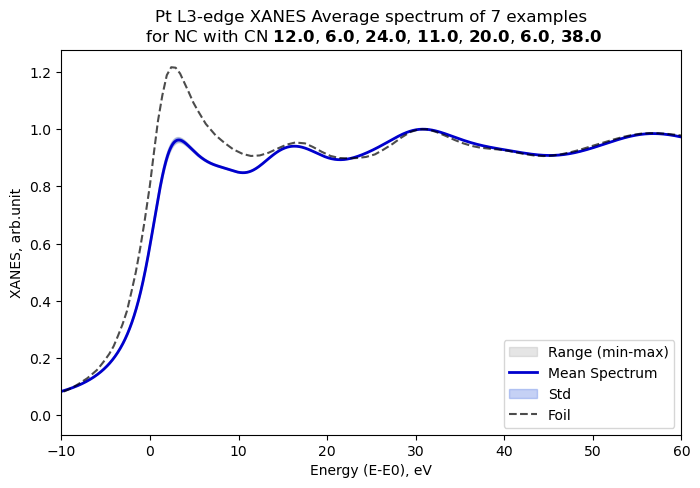

In [15]:
threshold = 6

CN4 = np.array(BASE_DF.CN.values.tolist())
unique, indices, inverse, counts = np.unique(CN4, return_counts=True, return_index=True, return_inverse=True, axis=0)

selected_group_ids = np.where(counts > threshold)[0]

for group_id in selected_group_ids:
    # Находим индексы строк в DataFrame, которые относятся к данной группе CN
    sample_indices = np.where(inverse == group_id)[0]
    tdf = BASE_DF.loc[sample_indices]
    plot_XANES(tdf,mode='CN')

In [16]:
# Из приведенных графиков видно, что для НК с одинаковым/близким кол-вом атомов в своем составе спектры демонстрируют достаточно большую вариативность
# При этом при использовании первых 4 КЧ в качестве дескриптора НК (как было предложено в работе (DOI: 10.1021/acs.jpclett.7b02364)
# Также наблюдается достаточно большая вариативность спектров, что свидетельствует о слабой применимости такого дескриптора.
# При использовании всех 7 доступных КЧ в качестве дескриптора вариативность спектров заметно снижается,
# однако для некоторых вариантов оставаясь по прежнему значимой.

## Посмотрим на распределение невязок (MSE) между теор. фольгой и другими НК в зависимости от кол-ва атомов и близости к поверхности

In [17]:
theor_foil_y = normded_spectra_y_cache[2045]
spectras_y = np.array(list(normded_spectra_y_cache.values()))
MSE = ((spectras_y - theor_foil_y)**2).sum(axis=1)/spectras_y.shape[1]
n_atoms = BASE_DF.Num_atoms.values

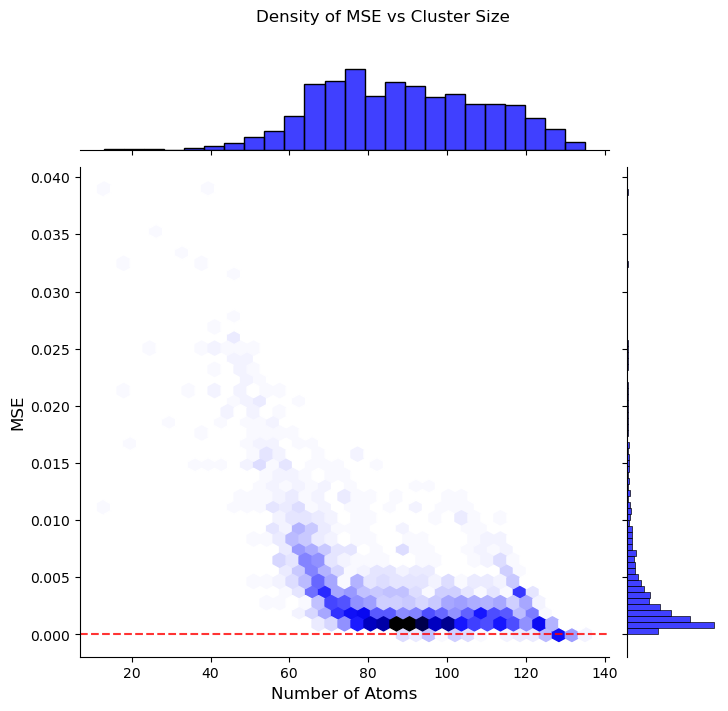

In [18]:
g = sns.jointplot(x=n_atoms, y=MSE, kind="hex", color="blue", height=7) # #4CB391
g.set_axis_labels('Number of Atoms', 'MSE', fontsize=12)

g.ax_joint.axhline(0, color='red', linestyle='--', linewidth=1.5, alpha=0.8)
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Density of MSE vs Cluster Size')

sp = Path(SAVE_IMAGE_PATH, 'NC_MSE_vs_Cluster_Size.png')
plt.savefig(sp, dpi=600)

plt.show()

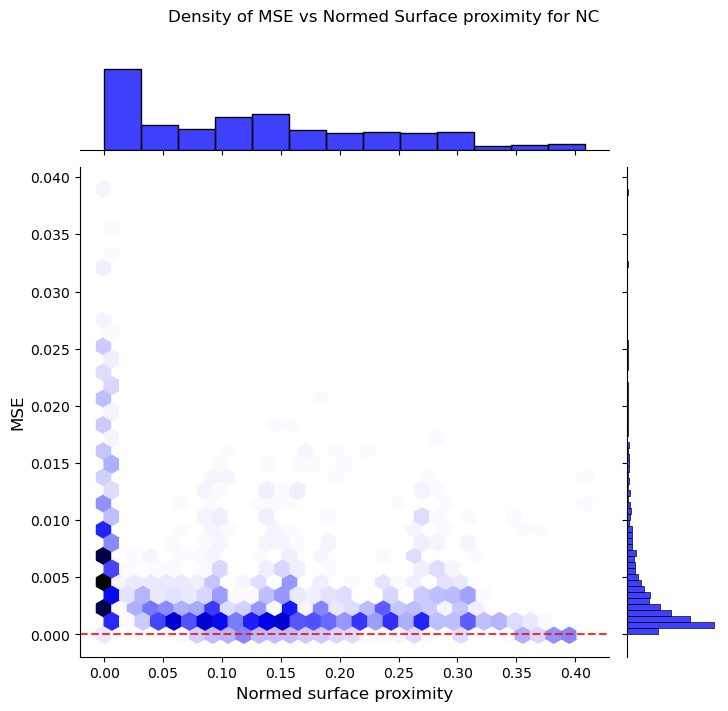

In [19]:
surface_proximity_normed = BASE_DF.surface_proximity_normed.values

g = sns.jointplot(x=surface_proximity_normed, y=MSE, kind="hex", color="blue", height=7) # #4CB391
g.set_axis_labels('Normed surface proximity', 'MSE', fontsize=12)

g.ax_joint.axhline(0, color='red', linestyle='--', linewidth=1.5, alpha=0.8)
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Density of MSE vs Normed Surface proximity for NC')

# plt.scatter(surface_proximity_normed,MSE, color='red',marker='d')

sp = Path(SAVE_IMAGE_PATH, 'NC_MSE_vs_Surface_proximity.png')
plt.savefig(sp, dpi=600)

plt.show()

In [20]:
# Из приведенных графиков видно, что уже при 80 атомов в своем составе многие НК демонстрируют почти идеальный спектр теор. фольги.
# Также видно что с уменьшением кол-ва атомов в составе НК вариативность спектров заметно растет 
# (что логично, т.к. все НК так или иначе поверхностные, за исключением одной структуры - теор.фольги).
# Наибольшее разнообразие спектров наблюдается для атомов лежащих прямо на поверхности НК.
# Также интерестно, что практически для любой удаленности от поверхности есть такой НК что практически совпадает с теор. фольгой.

### Посмотрим на парные распределения КЧ от PCA над спектрами, кол-ва атомов и близости к поверхности.

In [21]:
# В загруженные спектрах много точек, да и сам спектр по сути это сильно скоррелированный набор точек.
# Т.к. в последствии мы хотим предсказывать набор CN по спектру XANES в качестве наивного решения можно посмотреть на 
# графики рассеяния между PCA от спектра и целевыми КЧ, вдруг решение уже готово?

In [22]:
pca = PCA(0.999)
pca_y = pca.fit_transform(spectras_y)
pca_y.shape

(2151, 5)

In [23]:
CN = np.array(BASE_DF.CN.values.tolist())
CN1,CN2,CN3,CN4 = CN[:,0], CN[:,1], CN[:,2], CN[:,3]
data = {'SurfaceProximity':surface_proximity_normed, 
        'N_atoms':n_atoms,
        'PCA_Spectra_1':pca_y[:,0], 
        'PCA_Spectra_2':pca_y[:,1], 
        'PCA_Spectra_3':pca_y[:,2],
        'PCA_Spectra_4':pca_y[:,3],
        'PCA_Spectra_5':pca_y[:,4],
        'CN1':CN1, 
        'CN2':CN2, 
        'CN3':CN3, 
        'CN4':CN4,
       }
pcа_df = pd.DataFrame(data)

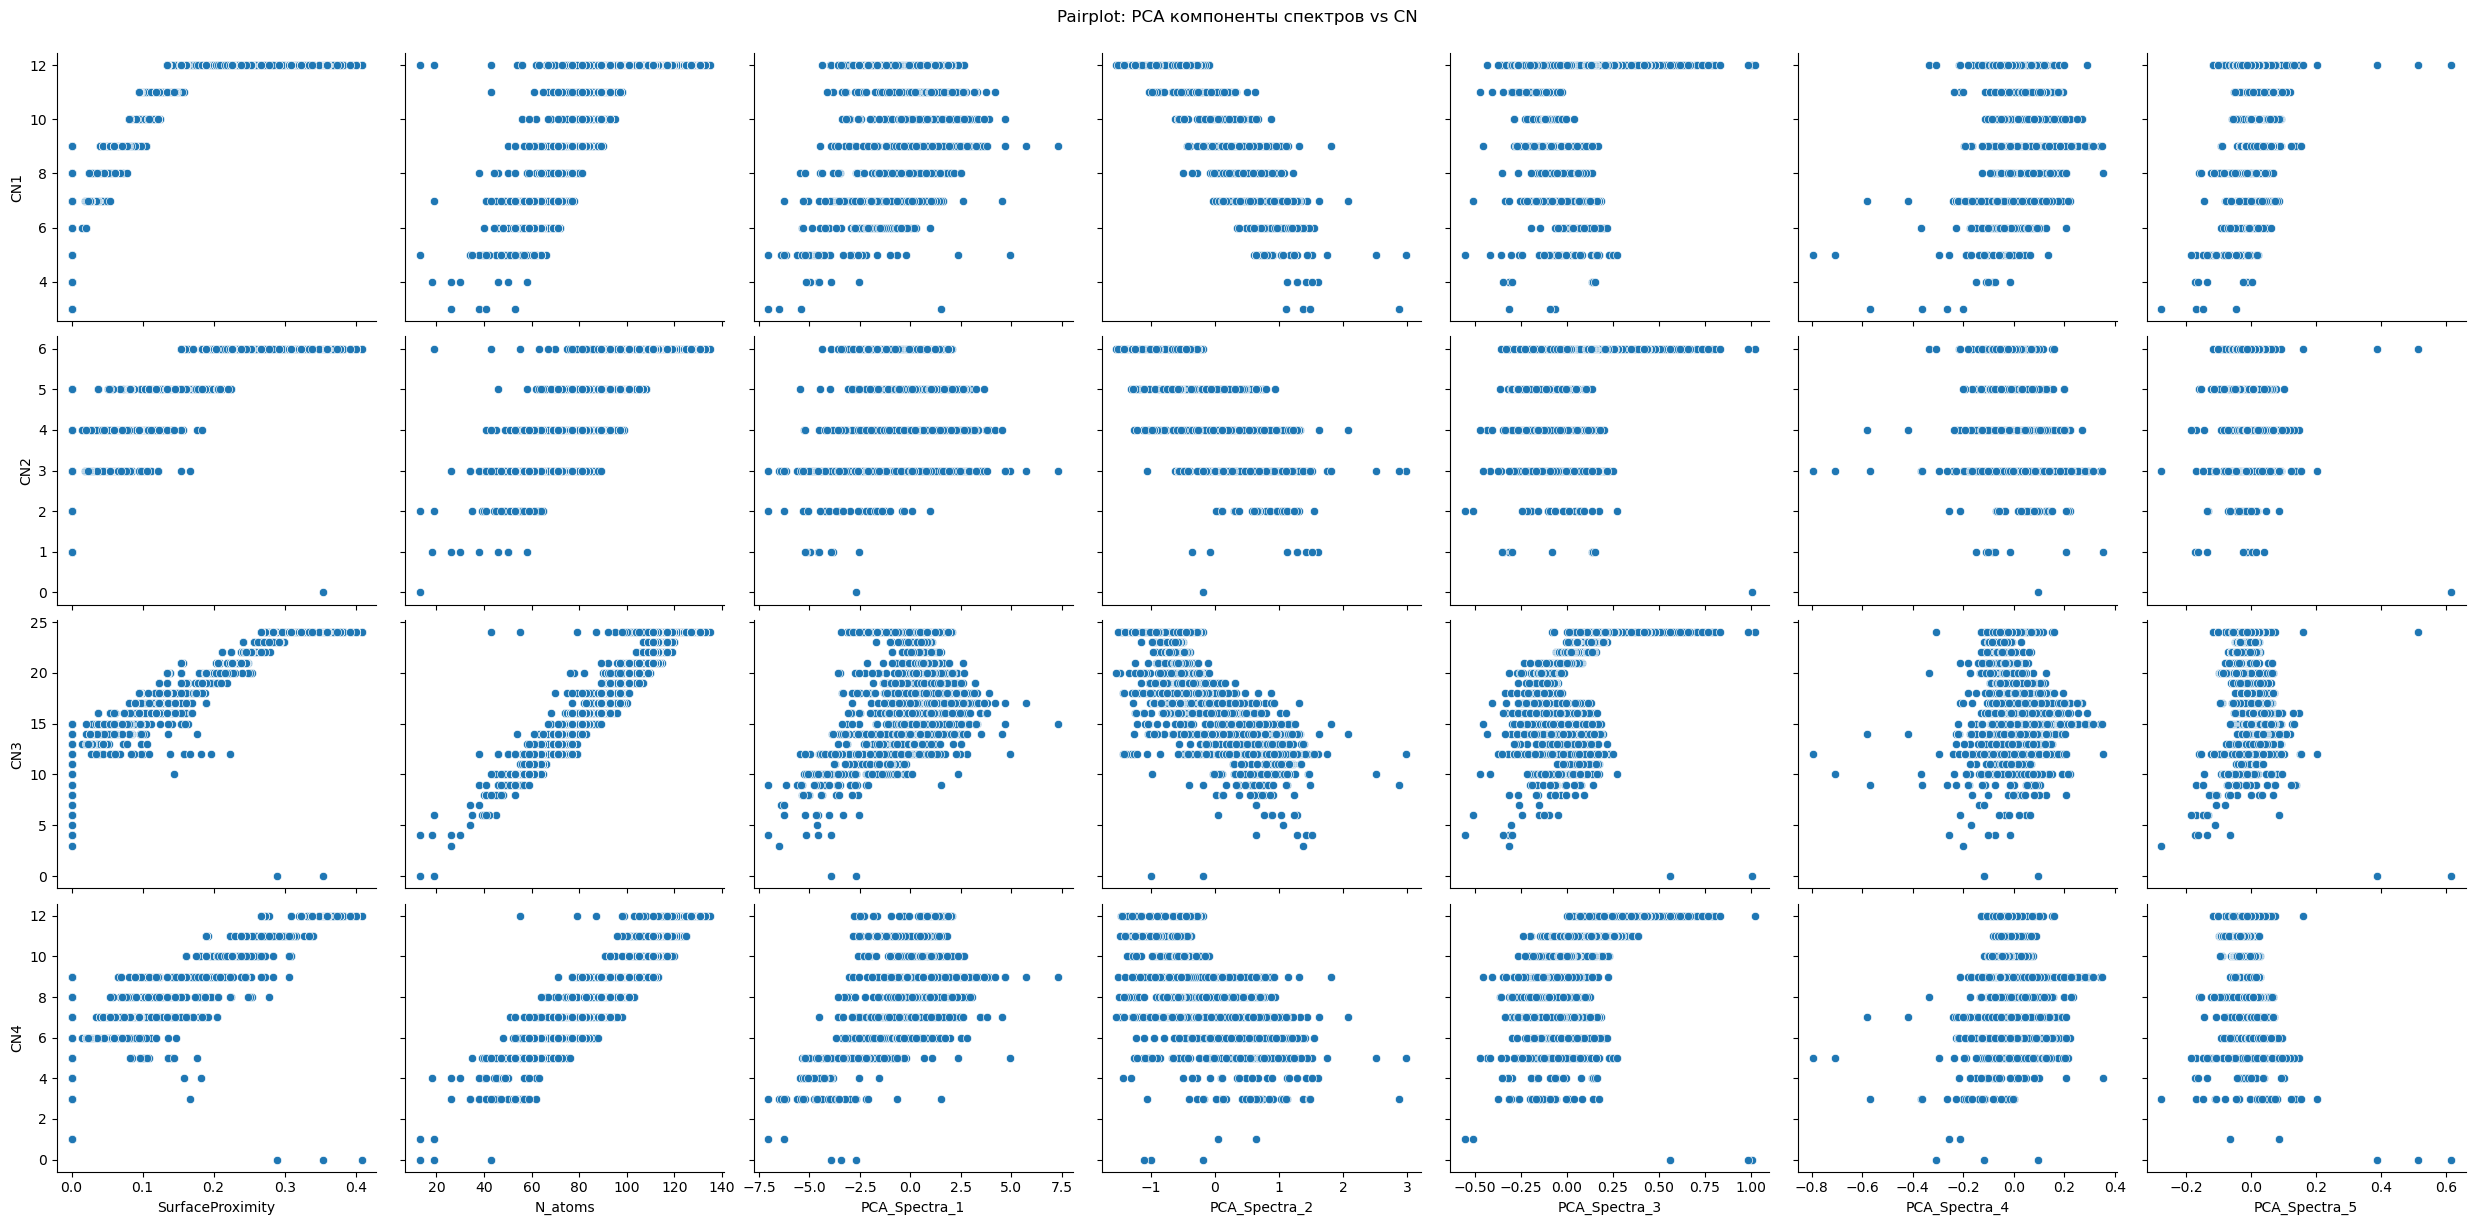

In [24]:
sns.pairplot(pcа_df,
             x_vars=['SurfaceProximity','N_atoms','PCA_Spectra_1', 'PCA_Spectra_2', 'PCA_Spectra_3', 'PCA_Spectra_4', 'PCA_Spectra_5'], 
             y_vars=['CN1', 'CN2', 'CN3', 'CN4'], 
             kind='scatter', 
             height=3, 
             aspect=1.2 
            )

plt.suptitle('Pairplot: PCA компоненты спектров vs CN', y=1.02)
plt.show()

## Посмотрим на корреляции точек спектра с CN

In [25]:
# Проинтерполируем наши спектры в новую более "редкую" сетку энергий.
E_new = np.arange(-10,60.5,1)
spectras_y_interp = np.array(list(map(lambda x: np.interp(E_new,theory_E_array,x).tolist(),spectras_y)))
# создадим словарь с необходимыми данными
data_corr = {'CN1':CN1, 
             'CN2':CN2, 
             'CN3':CN3, 
             'CN4':CN4}
for ind in range(spectras_y_interp.shape[1]):
    data_corr[-10+ind] = spectras_y_interp[:,ind]

corr_df = pd.DataFrame(data_corr)

corr_df = corr_df.corr().loc[['CN1','CN2','CN3','CN4']].drop(columns=['CN1','CN2','CN3','CN4'])
corr_df = abs(corr_df)

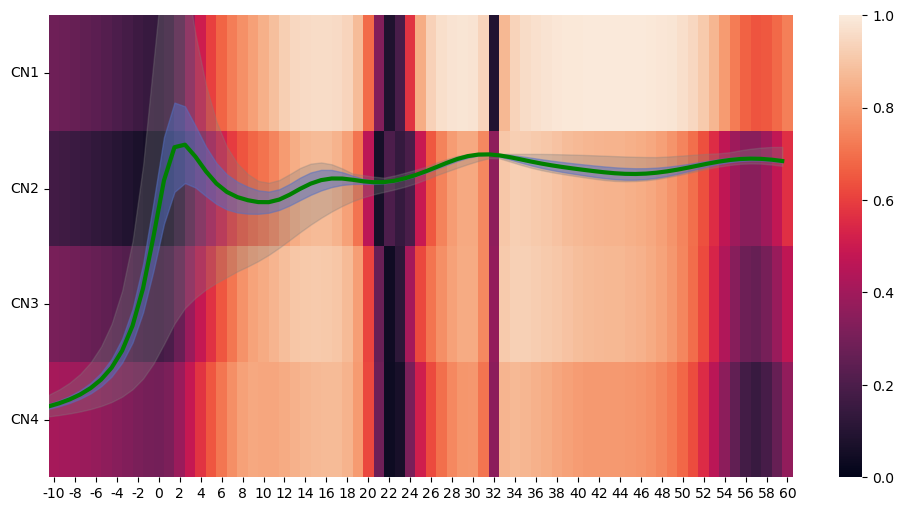

In [26]:
mean_y = np.mean(spectras_y_interp, axis=0)

std_y = np.std(spectras_y_interp, axis=0)

min_y = np.min(spectras_y_interp, axis=0)
max_y = np.max(spectras_y_interp, axis=0)

lower_bound = mean_y - std_y
upper_bound = mean_y + std_y

spectra_cor = lambda x: (1.5-x)*2.4

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(corr_df,vmin=0,vmax=1,ax=ax)
ax.plot(spectra_cor(mean_y), color='green', ls='-', lw=3)
ax.fill_between(np.arange(0,71),spectra_cor(upper_bound), spectra_cor(lower_bound), color='royalblue', alpha=0.5, label='Std')
ax.fill_between(np.arange(0,71),spectra_cor(min_y), spectra_cor(max_y), color='gray', alpha=0.3, label='Std')
plt.yticks(rotation=0)

sp = Path(SAVE_IMAGE_PATH,'CN_XANES_corr.png')
plt.savefig(sp, dpi=600)

plt.show()

In [27]:
# Несмотря на то что на графиках с PCA не видно ярко выраженных корреляций 
# (кол-во атомов и близость к поверхности выглядят как более качественные признаки)
# сопоставление отдельных точек полного спектра показывает значительную корреляцию с наборами КЧ.
# Скорее всего даже линейные модели смогут хорого описать искомую зависимость на уровне отдельных НК.
# Темная полоса на 32 eV обусловлена нормировкой по этой области.